# Renewable generation: data preparation
Student: Matilda Alford (ALFO0043)  
Date: 30-10-2026

We predict Open Electricity's `generation_renewable` (MW), whose definition includes some storage discharge. This is not a pure wind-and-solar forecast.


In [6]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

# Resolve paths from the repository root or inside A2.
for base in (Path.cwd(), *Path.cwd().parents):
    if (base / 'A2/src/renewables/features.py').is_file():
        PROJECT_DIR = base
        break
else:
    raise FileNotFoundError('Open this notebook from within the repository.')

sys.path.insert(0, str(PROJECT_DIR / 'A2/src'))
from renewables.features import (
    TARGET,
    load_renewable_data,
    coverage_by_year,
    prepare_forecast_data,
    split_forecast_data,
)


## Coverage Inspecion
Load cleaned data rather than A1 transformed data, because the latter applies a curtailment-based cutoff. Retain the full history for inspection. Missing is not zero. Yearly summaries describe the covered hours only; 2026 is a partial year.


In [7]:
data = load_renewable_data()
print('Hourly rows:', len(data))
print('First hour:', data['timestamp'].min())
print('Last hour:', data['timestamp'].max())
print('Missing generation:', data[TARGET].isna().sum())
display(coverage_by_year(data))


Hourly rows: 234312
First hour: 2000-01-01 00:00:00+10:00
Last hour: 2026-09-23 23:00:00+10:00
Missing generation: 452


,hours,available_hours,mean_mw,max_mw,missing_hours,missing_percent
timestamp,,,,,,
2000,8784,8784,623.831862,3049.666667,0,0.000000
2001,8760,8760,385.788654,2579.666667,0,0.000000
2002,8760,8760,222.200258,938.022500,0,0.000000
2003,8760,8760,326.229843,869.380833,0,0.000000
2004,8784,8784,123.080998,1020.305000,0,0.000000
2005,8760,8760,323.174308,918.255833,0,0.000000
2006,8760,8760,245.639838,1032.632500,0,0.000000
2007,8760,8760,164.779969,872.788442,0,0.000000
2008,8784,8784,153.363349,978.261950,0,0.000000


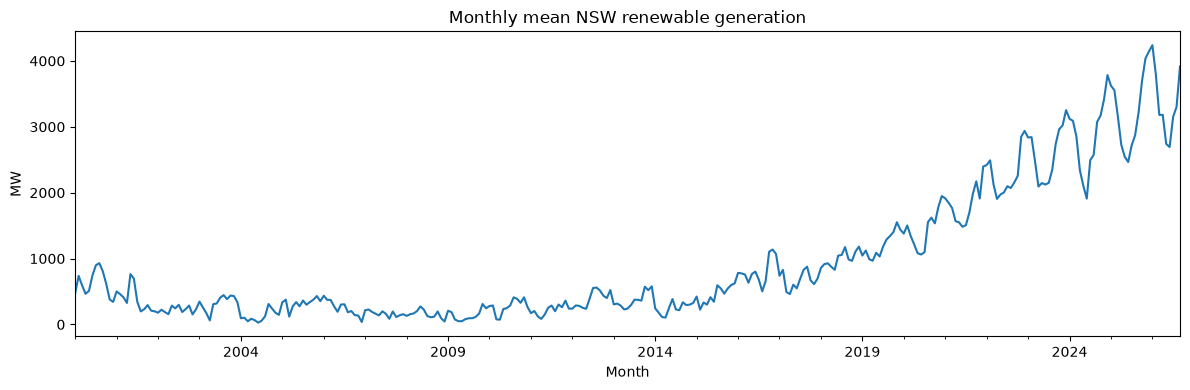

In [8]:
monthly_generation = data.set_index('timestamp')[TARGET].resample('MS').mean()
monthly_generation.plot(figsize=(12, 4), title='Monthly mean NSW renewable generation')
plt.ylabel('MW')
plt.xlabel('Month')
plt.tight_layout()
plt.show()


## Forecast Setup
Each issue time t assumes the completed hour's measurement is available.
Inputs are current renewable generation, 1/24/168-hour lags, previous-24-hour mean and standard deviation, and Sydney-local cyclical time features. The lag/rolling and time functions are reused from Shiv's A1 helper functions; see `features.py` for attribution.

Targets are the next 24 hourly readings (t+1 to t+24). No interpolation,
scaling or model fitting occurs here. Incomplete feature or target rows are excluded after shifts are calculated on the continuous timeline.


In [9]:
prepared, feature_columns, target_columns = prepare_forecast_data(data)
print('Complete forecast examples:', len(prepared))
print('Rows excluded (history, missing values or unavailable future):', len(data) - len(prepared))
print('Input features:', feature_columns)
print('Forecast horizons:', len(target_columns))
display(prepared.head())


Complete forecast examples: 231665
Rows excluded (history, missing values or unavailable future): 2647
Input features: ['generation_renewable', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'is_weekend', 'generation_renewable_lag_1h', 'generation_renewable_lag_24h', 'generation_renewable_lag_168h', 'generation_renewable_rolling_mean_24h', 'generation_renewable_rolling_std_24h']
Forecast horizons: 24


,timestamp,generation_renewable,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,is_weekend,generation_renewable_lag_1h,...,generation_renewable_next_15h,generation_renewable_next_16h,generation_renewable_next_17h,generation_renewable_next_18h,generation_renewable_next_19h,generation_renewable_next_20h,generation_renewable_next_21h,generation_renewable_next_22h,generation_renewable_next_23h,generation_renewable_next_24h
0,2000-01-08 00:00:00+10:00,46.0,0.258819,0.965926,-0.974928,-0.222521,0.0,1.0,1,89.333333,...,72.500000,50.416667,46.0,46.0,46.0,46.0,46.0,46.0,46.0,46.0
1,2000-01-08 01:00:00+10:00,46.0,0.500000,0.866025,-0.974928,-0.222521,0.0,1.0,1,46.000000,...,50.416667,46.000000,46.0,46.0,46.0,46.0,46.0,46.0,46.0,46.0
2,2000-01-08 02:00:00+10:00,46.0,0.707107,0.707107,-0.974928,-0.222521,0.0,1.0,1,46.000000,...,46.000000,46.000000,46.0,46.0,46.0,46.0,46.0,46.0,46.0,46.0
3,2000-01-08 03:00:00+10:00,46.0,0.866025,0.500000,-0.974928,-0.222521,0.0,1.0,1,46.000000,...,46.000000,46.000000,46.0,46.0,46.0,46.0,46.0,46.0,46.0,46.0
4,2000-01-08 04:00:00+10:00,46.0,0.965926,0.258819,-0.974928,-0.222521,0.0,1.0,1,46.000000,...,46.000000,46.000000,46.0,46.0,46.0,46.0,46.0,46.0,46.0,46.0


## Chronological Boundaries
Initial fixed calendar split: training before 2024, validation in 2024, and held-out testing from 2025 onward. 

In [10]:
validation_start = pd.Timestamp('2024-01-01', tz='Etc/GMT-10')
test_start = pd.Timestamp('2025-01-01', tz='Etc/GMT-10')
splits = split_forecast_data(prepared, validation_start, test_start)

split_summary = pd.DataFrame([
    {
        'split': name,
        'examples': len(part),
        'first_issue': part['timestamp'].min(),
        'last_issue': part['timestamp'].max(),
        'last_target': part['timestamp'].max() + pd.Timedelta(hours=24),
    }
    for name, part in splits.items()
])
display(split_summary)


,split,examples,first_issue,last_issue,last_target
0,train,207737,2000-01-08 00:00:00+10:00,2023-12-30 23:00:00+10:00,2023-12-31 23:00:00+10:00
1,validation,8760,2024-01-01 00:00:00+10:00,2024-12-30 23:00:00+10:00,2024-12-31 23:00:00+10:00
2,test,15120,2025-01-01 00:00:00+10:00,2026-09-22 23:00:00+10:00,2026-09-23 23:00:00+10:00


## Implementing ML Models
Compare a same-hour-yesterday baseline with Random Forest and gradient boosting forecasting models. Evaluate MAE/RMSE overall and by forecast horizon. Save the selected model and its input schema separately from this preparation notebook.

Later, combine renewable forecasts with Oli's part.


## Train and compare forecasting models

- Each forecast contains 24 hourly outputs. Training may take several minutes
- No scaling is needed for these tree models
- Gradient boosting uses one model per horizon, with random internal early stopping disabled

The test period remains held out. Saved files go to `A2/outputs/renewables/`.


In [11]:
from renewables.train import compare_models

comparison, horizon_errors, selected_model = compare_models(
    data, splits, feature_columns, target_columns
)
display(comparison)
print('Selected ML model:', selected_model['model_name'])
print('Training window:', selected_model['window'])
print('Validation MAE (MW):', selected_model['validation_mae_mw'])


Training random_forest: full_history, 207,737 examples
Training gradient_boosting: full_history, 207,737 examples
Training random_forest: recent_history, 43,800 examples
Training gradient_boosting: recent_history, 43,800 examples


,model,window,training_rows,validation_rows,mae_mw,rmse_mw
0,gradient_boosting,recent_history,43800,8760,568.513732,787.267931
1,gradient_boosting,full_history,207737,8760,583.512092,804.262958
2,random_forest,recent_history,43800,8760,588.929623,816.376375
3,random_forest,full_history,207737,8760,589.595486,816.983070
4,same_hour_yesterday,previous_day,0,8760,603.015875,828.520945


Selected ML model: gradient_boosting
Training window: recent_history
Validation MAE (MW): 568.5137316322928


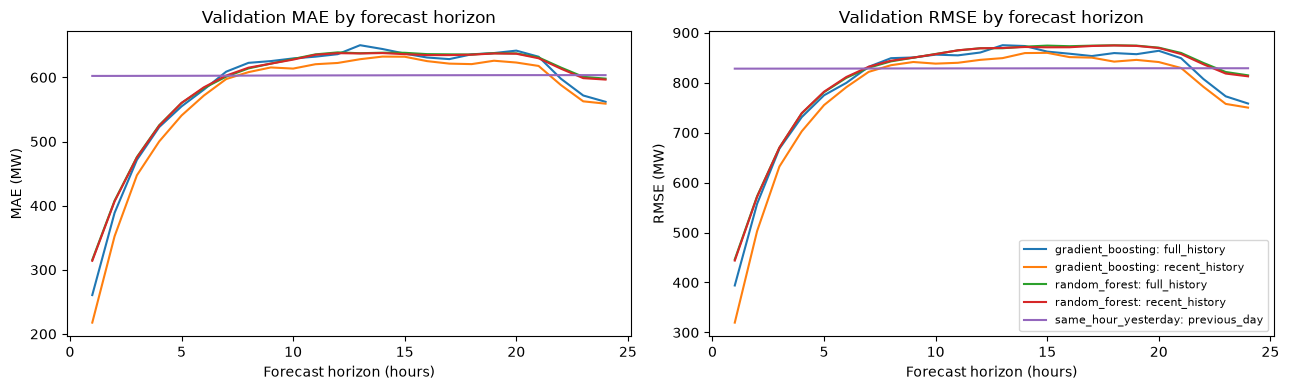

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (model, window), group in horizon_errors.groupby(['model', 'window']):
    label = f'{model}: {window}'
    axes[0].plot(group['horizon_hours'], group['mae_mw'], label=label)
    axes[1].plot(group['horizon_hours'], group['rmse_mw'], label=label)
for axis, metric in zip(axes, ['MAE', 'RMSE']):
    axis.set_xlabel('Forecast horizon (hours)')
    axis.set_ylabel(f'{metric} (MW)')
    axis.set_title(f'Validation {metric} by forecast horizon')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


In [13]:
import joblib
import numpy as np

from renewables.train import OUTPUT_DIR, same_hour_yesterday

model_bundle = joblib.load(OUTPUT_DIR / 'selected_model.joblib')
validation_data = splits['validation'].copy()
baseline_predictions = same_hour_yesterday(data, validation_data['timestamp'])
complete_baseline = np.isfinite(baseline_predictions).all(axis=1)
validation_data = validation_data.loc[complete_baseline].reset_index(drop=True)
baseline_predictions = baseline_predictions[complete_baseline]

# Check that the saved model belongs to the preparation and period in this notebook.
assert model_bundle['feature_columns'] == feature_columns
assert model_bundle['target_columns'] == target_columns
assert validation_data['timestamp'].min().isoformat() == model_bundle['validation_first_issue']
assert validation_data['timestamp'].max().isoformat() == model_bundle['validation_last_issue']

actual_generation = validation_data[target_columns].to_numpy()
model_predictions = model_bundle['model'].predict(validation_data[feature_columns])
print('Selected model:', model_bundle['model_name'], model_bundle['window'])
print('Validation forecast origins:', len(validation_data))


Selected model: gradient_boosting recent_history
Validation forecast origins: 8760


### Four fixed seasonal forecast examples
Choose the same issue time on January 15, April 15, July 15 and October 15 of
the validation year, before inspecting errors. These are illustrative examples,
not a representative performance estimate. Each panel shows one complete
24-hour forecast issued at midnight in fixed AEST; the horizontal axis uses
Sydney local time, including daylight saving.


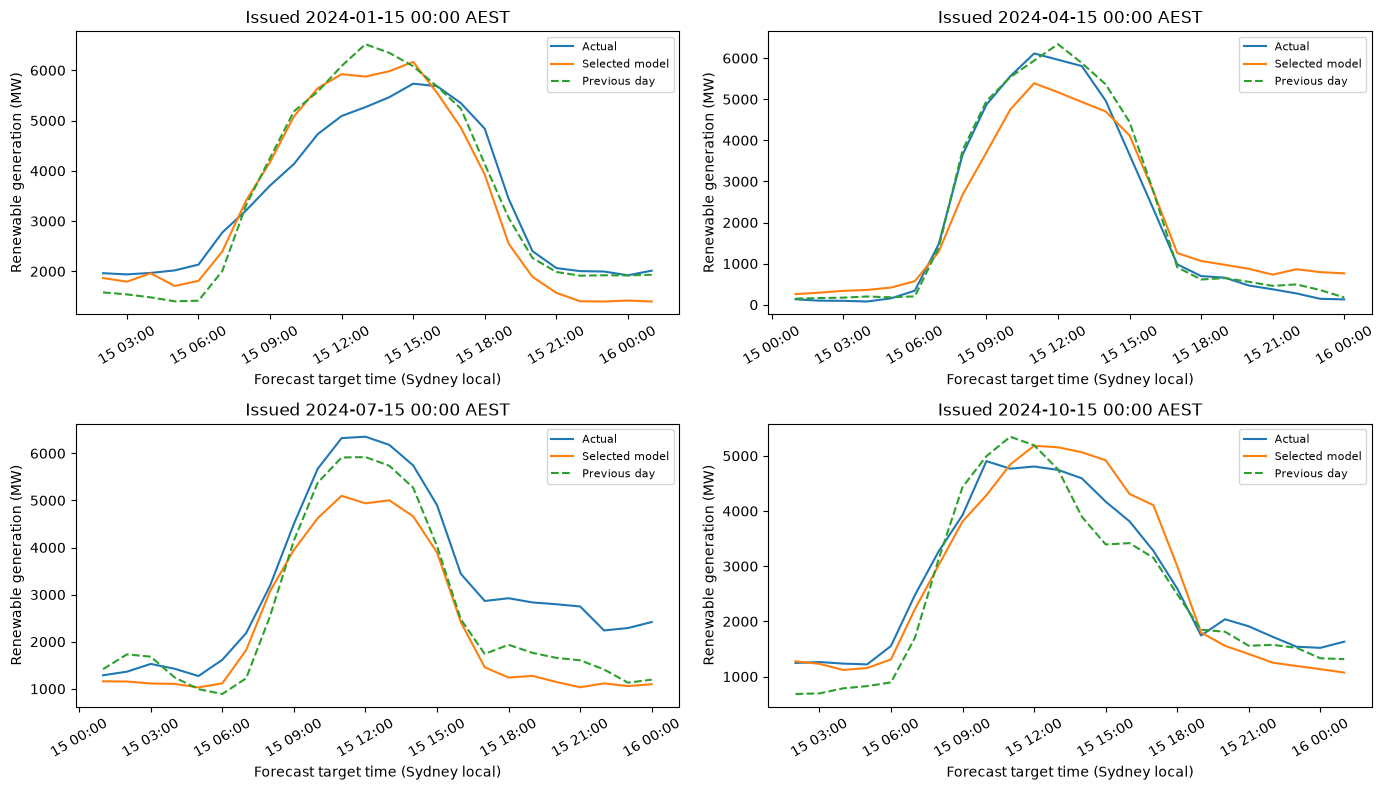

In [14]:
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo

validation_year = validation_data['timestamp'].dt.year.min()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for axis, month in zip(axes.flat, [1, 4, 7, 10]):
    issue_time = pd.Timestamp(year=validation_year, month=month, day=15,
                              tz=validation_data['timestamp'].dt.tz)
    matches = np.flatnonzero(validation_data['timestamp'].eq(issue_time))
    if len(matches) == 0:
        axis.text(0.5, 0.5, f'No complete forecast at {issue_time}',
                  ha='center', transform=axis.transAxes)
        continue
    row = matches[0]
    forecast_times = pd.date_range(issue_time + pd.Timedelta(hours=1), periods=24, freq='h')
    forecast_times = forecast_times.tz_convert('Australia/Sydney')
    axis.plot(forecast_times, actual_generation[row], label='Actual')
    axis.plot(forecast_times, model_predictions[row], label='Selected model')
    axis.plot(forecast_times, baseline_predictions[row], '--', label='Previous day')
    axis.set_title(f'Issued {issue_time:%Y-%m-%d %H:%M} AEST')
    axis.set_ylabel('Renewable generation (MW)')
    axis.set_xlabel('Forecast target time (Sydney local)')
    axis.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M', tz=ZoneInfo('Australia/Sydney')))
    axis.tick_params(axis='x', rotation=30)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()


### Errors by target hour and season
Each row below represents one forecast origin and one lead time. The same actual
hour can be predicted from several origins, so rows are not independent samples.
Aggregate scores describe all 24 lead times equally, rather than unique hours.
Calendar groups refer to the **forecast target time**, converted to Sydney local
time. Australian seasons are summer (Dec–Feb), autumn (Mar–May), winter
(Jun–Aug) and spring (Sep–Nov). These are descriptive comparisons, not
statistical significance tests.


forecasts  mae_mw  bias_mw  rmse_mw
season model                                              
Autumn Previous day        53016  487.60    12.34   673.30
       Selected model      53016  488.30   -53.36   656.05
Spring Previous day        52392  649.53    13.18   890.81
       Selected model      52392  650.08  -205.09   878.37
Summer Previous day        51840  690.26   -13.29   937.97
       Selected model      51840  644.63  -262.71   906.32
Winter Previous day        52992  587.15   -16.80   790.35
       Selected model      52992  493.66  -101.88   679.70

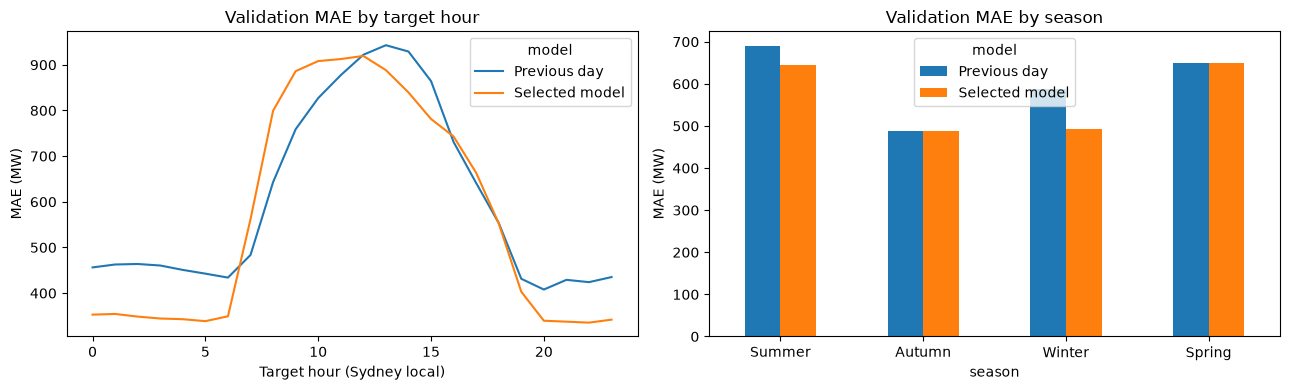

In [15]:
error_parts = []
for name, predictions in [('Selected model', model_predictions),
                          ('Previous day', baseline_predictions)]:
    for horizon in range(1, 25):
        part = pd.DataFrame({
            'issue_time': validation_data['timestamp'],
            'target_time': validation_data['timestamp'] + pd.Timedelta(hours=horizon),
            'horizon_hours': horizon,
            'model': name,
            'actual_mw': actual_generation[:, horizon - 1],
            'predicted_mw': predictions[:, horizon - 1],
        })
        error_parts.append(part)
forecast_errors_long = pd.concat(error_parts, ignore_index=True)
local_target = forecast_errors_long['target_time'].dt.tz_convert('Australia/Sydney')
forecast_errors_long['target_hour'] = local_target.dt.hour
season_by_month = {12: 'Summer', 1: 'Summer', 2: 'Summer',
                   3: 'Autumn', 4: 'Autumn', 5: 'Autumn',
                   6: 'Winter', 7: 'Winter', 8: 'Winter',
                   9: 'Spring', 10: 'Spring', 11: 'Spring'}
forecast_errors_long['season'] = local_target.dt.month.map(season_by_month)
forecast_errors_long['error_mw'] = (
    forecast_errors_long['predicted_mw'] - forecast_errors_long['actual_mw']
)
forecast_errors_long['absolute_error_mw'] = forecast_errors_long['error_mw'].abs()
forecast_errors_long['squared_error'] = forecast_errors_long['error_mw'] ** 2

# This small notebook helper summarises the same metrics for each grouping.
def summarise_errors(frame, groups):
    summary = frame.groupby(groups).agg(
        forecasts=('error_mw', 'size'),
        mae_mw=('absolute_error_mw', 'mean'),
        mse=('squared_error', 'mean'),
        bias_mw=('error_mw', 'mean'),
    )
    summary['rmse_mw'] = np.sqrt(summary.pop('mse'))
    return summary

hourly_errors = summarise_errors(forecast_errors_long, ['target_hour', 'model'])
seasonal_errors = summarise_errors(forecast_errors_long, ['season', 'model'])
display(seasonal_errors.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hourly_errors['mae_mw'].unstack('model').plot(ax=axes[0])
axes[0].set_title('Validation MAE by target hour')
axes[0].set_xlabel('Target hour (Sydney local)')
axes[0].set_ylabel('MAE (MW)')
seasonal_errors['mae_mw'].unstack('model').reindex(
    ['Summer', 'Autumn', 'Winter', 'Spring']
).plot.bar(ax=axes[1], rot=0)
axes[1].set_title('Validation MAE by season')
axes[1].set_ylabel('MAE (MW)')
plt.tight_layout()
plt.show()


### Low-generation periods
Define low generation as at or below the 20th percentile of observed renewable
MW in the selected model's training window. This is an exploratory threshold,
not an operational sufficiency target. Derive it from hourly observations rather
than repeated forecast targets. No validation/test outcomes set the threshold.

The groups use actual validation generation to diagnose performance after the
fact; they are not information available to the forecasting model. Low renewable
output alone does not establish insufficient supply. Examine signed bias as well
as MAE, since overprediction can make later sufficiency assessments optimistic.


Exploratory low-generation threshold: 771.6 MW


forecasts  mae_mw  bias_mw  rmse_mw
generation_group model                                              
Low generation   Previous day        25334  437.99   371.58   577.63
                 Selected model      25334  434.24   430.14   500.45
Other generation Previous day       184906  625.63   -52.18   857.19
                 Selected model     184906  586.91  -235.20   818.78

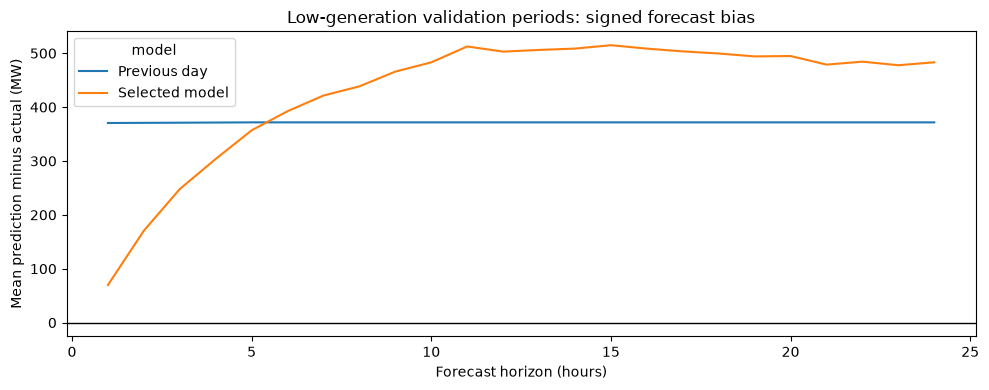

In [16]:
training_start = pd.Timestamp(model_bundle['training_first_issue'])
training_end = pd.Timestamp(model_bundle['training_last_issue']) + pd.Timedelta(hours=24)
training_observations = data.loc[
    data['timestamp'].between(training_start, training_end), TARGET
].dropna()
low_generation_threshold = training_observations.quantile(0.20)
print(f'Exploratory low-generation threshold: {low_generation_threshold:.1f} MW')
forecast_errors_long['generation_group'] = np.where(
    forecast_errors_long['actual_mw'] <= low_generation_threshold,
    'Low generation', 'Other generation'
)
generation_errors = summarise_errors(
    forecast_errors_long, ['generation_group', 'model']
)
display(generation_errors.round(2))

low_horizon_errors = summarise_errors(
    forecast_errors_long.loc[forecast_errors_long['generation_group'] == 'Low generation'],
    ['horizon_hours', 'model']
)
low_horizon_errors['bias_mw'].unstack('model').plot(
    figsize=(10, 4), title='Low-generation validation periods: signed forecast bias'
)
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Forecast horizon (hours)')
plt.ylabel('Mean prediction minus actual (MW)')
plt.tight_layout()
plt.show()


## Experiment: previous 24 hourly generation readings
Keep the selected model's algorithm, hyperparameters and training window fixed.
Add missing lags from 1 through 24 hours, alongside the existing current value,
24/168-hour lags, rolling statistics and time features. Construct shifts on the
original continuous timeline before matching prepared examples by timestamp.

In [17]:
from sklearn.base import clone

# Do not shift prepared rows: removed rows could make hourly lags misaligned.
hourly_history = data.set_index('timestamp')[TARGET]
lag_history = pd.DataFrame(index=hourly_history.index)
extra_feature_columns = []
for hour in range(1, 25):
    column = f'{TARGET}_lag_{hour}h'
    if column not in feature_columns:
        lag_history[column] = hourly_history.shift(hour)
        extra_feature_columns.append(column)

experiment_data = prepared.merge(
    lag_history.reset_index(), on='timestamp', how='left', validate='one_to_one'
)
experiment_features = feature_columns + extra_feature_columns
experiment_data = experiment_data.dropna(subset=experiment_features)

# Match the selected training window and the validation origins already assessed.
experiment_train = experiment_data.loc[
    experiment_data['timestamp'].between(
        pd.Timestamp(model_bundle['training_first_issue']),
        pd.Timestamp(model_bundle['training_last_issue'])
    )
].copy()
experiment_validation = experiment_data.loc[
    experiment_data['timestamp'].isin(validation_data['timestamp'])
].copy().reset_index(drop=True)
if experiment_train.empty or experiment_validation.empty:
    raise ValueError('The history experiment needs complete training and validation rows.')

experiment_actual = experiment_validation[target_columns].to_numpy()
experiment_baseline = same_hour_yesterday(data, experiment_validation['timestamp'])
assert np.isfinite(experiment_baseline).all()
print('Additional hourly lags:', len(extra_feature_columns))
print('Training examples:', len(experiment_train))
print('Validation examples:', len(experiment_validation))

original_inputs_model = clone(model_bundle['model'])
hourly_inputs_model = clone(model_bundle['model'])
print('Fitting original inputs...', flush=True)
original_inputs_model.fit(experiment_train[feature_columns], experiment_train[target_columns])
print('Fitting previous-24-hour inputs...', flush=True)
hourly_inputs_model.fit(experiment_train[experiment_features], experiment_train[target_columns])
experiment_predictions = {
    'Original inputs': original_inputs_model.predict(experiment_validation[feature_columns]),
    'Previous 24 hours': hourly_inputs_model.predict(experiment_validation[experiment_features]),
    'Previous day baseline': experiment_baseline,
}


Additional hourly lags: 22
Training examples: 43800
Validation examples: 8760
Fitting original inputs...
Fitting previous-24-hour inputs...


,model,group,forecasts,mae_mw,rmse_mw,bias_mw
0,Original inputs,All generation,210240,568.51,787.27,-155.02
1,Original inputs,Low generation,25334,434.24,500.45,430.14
2,Previous 24 hours,All generation,210240,529.52,739.42,-151.62
3,Previous 24 hours,Low generation,25334,403.80,476.96,397.49
4,Previous day baseline,All generation,210240,603.02,828.52,-1.12
5,Previous day baseline,Low generation,25334,437.99,577.63,371.58


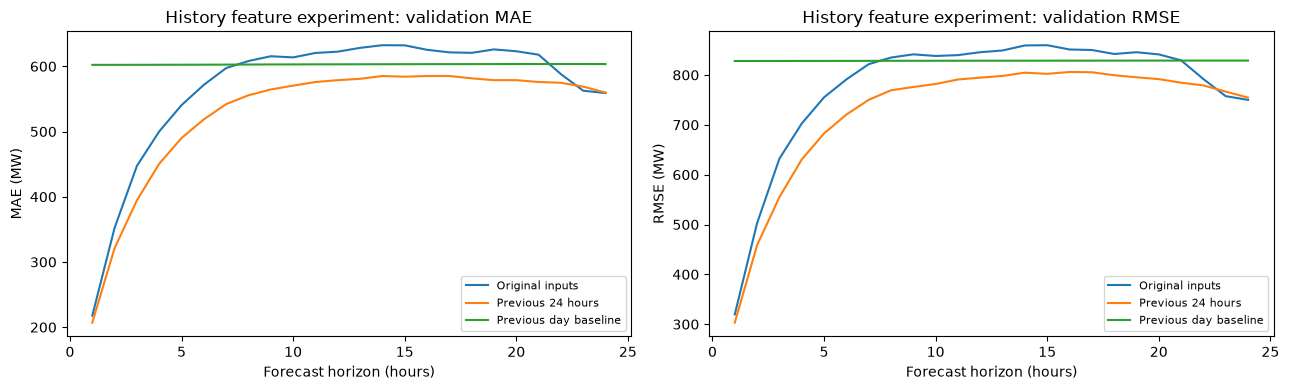

In [18]:
from renewables.train import forecast_errors

experiment_summaries = []
experiment_horizons = []
low_mask = experiment_actual <= low_generation_threshold
for name, predictions in experiment_predictions.items():
    horizon_report = forecast_errors(experiment_actual, predictions)
    horizon_report['model'] = name
    experiment_horizons.append(horizon_report)
    for group, mask in [('All generation', np.ones_like(low_mask, dtype=bool)),
                        ('Low generation', low_mask)]:
        errors = (predictions - experiment_actual)[mask]
        if errors.size == 0:
            continue
        experiment_summaries.append({
            'model': name, 'group': group, 'forecasts': errors.size,
            'mae_mw': np.abs(errors).mean(),
            'rmse_mw': np.sqrt((errors ** 2).mean()),
            'bias_mw': errors.mean(),
        })
experiment_summary = pd.DataFrame(experiment_summaries)
experiment_horizon_errors = pd.concat(experiment_horizons, ignore_index=True)
display(experiment_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, group in experiment_horizon_errors.groupby('model'):
    axes[0].plot(group['horizon_hours'], group['mae_mw'], label=name)
    axes[1].plot(group['horizon_hours'], group['rmse_mw'], label=name)
for axis, metric in zip(axes, ['MAE', 'RMSE']):
    axis.set_xlabel('Forecast horizon (hours)')
    axis.set_ylabel(f'{metric} (MW)')
    axis.set_title(f'History feature experiment: validation {metric}')
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Save this experiment separately; retain the original selected model.
experiment_dir = OUTPUT_DIR / 'history_experiment'
experiment_dir.mkdir(parents=True, exist_ok=True)
experiment_summary.to_csv(experiment_dir / 'validation_comparison.csv', index=False)
experiment_horizon_errors.to_csv(experiment_dir / 'validation_by_horizon.csv', index=False)


## Review the expanded-history candidate
Compare the same four fixed seasonal issue times used earlier. The original
model, expanded-history model and baseline use matching validation origins.
Run the history experiment above first; these cells do not refit models or
access test data. The table reports improvement against the baseline at each
lead time: positive percentages mean lower MAE.


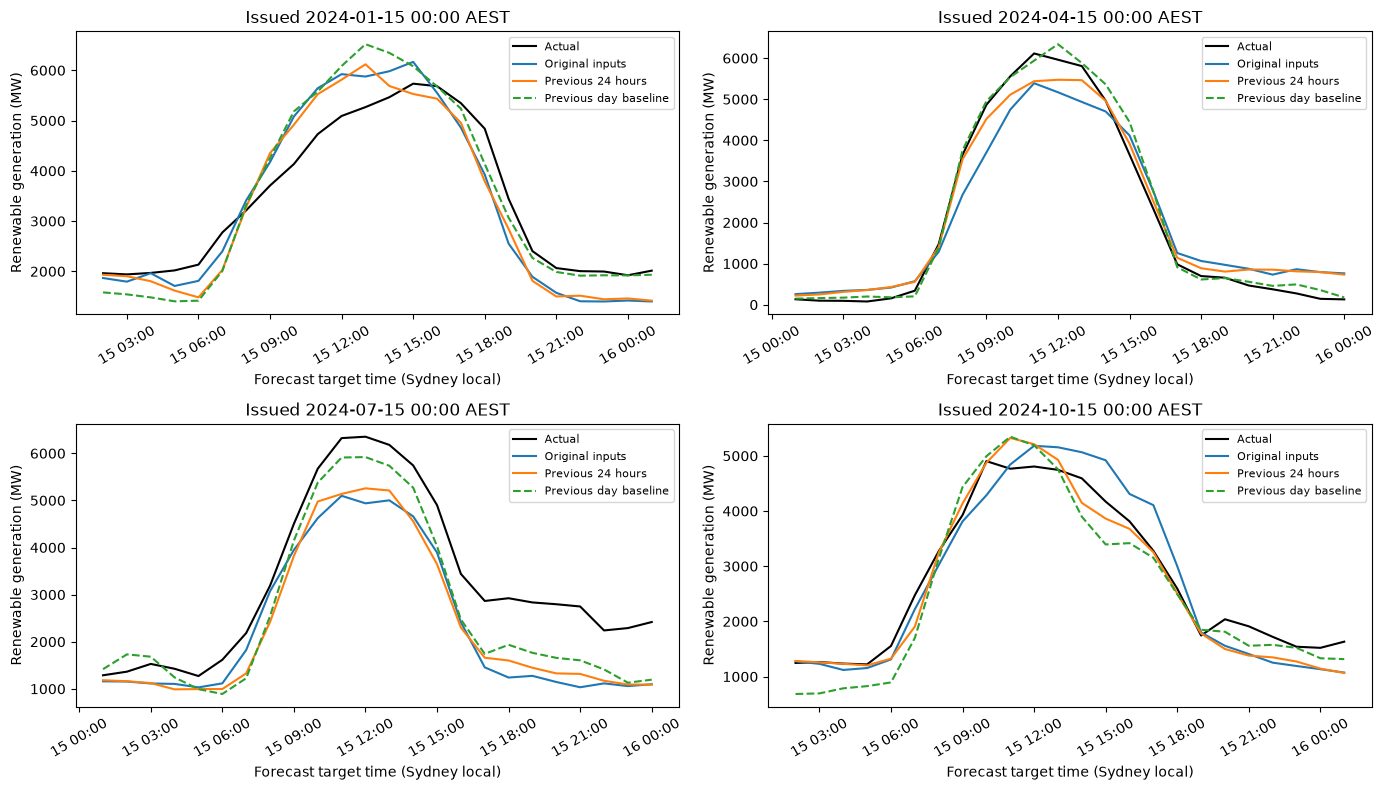

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for axis, month in zip(axes.flat, [1, 4, 7, 10]):
    issue_time = pd.Timestamp(year=validation_year, month=month, day=15,
                              tz=experiment_validation['timestamp'].dt.tz)
    matches = np.flatnonzero(experiment_validation['timestamp'].eq(issue_time))
    if len(matches) == 0:
        axis.text(0.5, 0.5, f'No complete forecast at {issue_time}',
                  ha='center', transform=axis.transAxes)
        continue
    row = matches[0]
    forecast_times = pd.date_range(issue_time + pd.Timedelta(hours=1), periods=24, freq='h')
    forecast_times = forecast_times.tz_convert('Australia/Sydney')
    axis.plot(forecast_times, experiment_actual[row], color='black', label='Actual')
    for name, predictions in experiment_predictions.items():
        axis.plot(forecast_times, predictions[row], label=name,
                  linestyle='--' if name == 'Previous day baseline' else '-')
    axis.set_title(f'Issued {issue_time:%Y-%m-%d %H:%M} AEST')
    axis.set_ylabel('Renewable generation (MW)')
    axis.set_xlabel('Forecast target time (Sydney local)')
    axis.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M', tz=ZoneInfo('Australia/Sydney')))
    axis.tick_params(axis='x', rotation=30)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [20]:
horizon_comparison = experiment_horizon_errors.pivot(
    index='horizon_hours', columns='model', values='mae_mw'
)
horizon_comparison['improvement_over_baseline_percent'] = 100 * (
    1 - horizon_comparison['Previous 24 hours'] /
    horizon_comparison['Previous day baseline']
)
horizon_comparison['improvement_over_original_percent'] = 100 * (
    1 - horizon_comparison['Previous 24 hours'] /
    horizon_comparison['Original inputs']
)
display(horizon_comparison.round(2))
winning_horizons = horizon_comparison.index[
    horizon_comparison['Previous 24 hours'] < horizon_comparison['Previous day baseline']
].tolist()
print('Lead times beating the baseline (hours):', winning_horizons)
horizon_comparison.to_csv(experiment_dir / 'horizon_improvements.csv')


model,Original inputs,Previous 24 hours,Previous day baseline,improvement_over_baseline_percent,improvement_over_original_percent
horizon_hours,,,,,
1,217.61,207.01,602.25,65.63,4.87
2,352.32,321.25,602.29,46.66,8.82
3,447.37,394.52,602.33,34.50,11.81
4,500.16,450.67,602.39,25.19,9.89
5,540.54,490.03,602.46,18.66,9.34
6,571.66,518.67,602.53,13.92,9.27
7,597.36,542.08,602.63,10.05,9.25
8,608.17,555.61,602.78,7.83,8.64
9,615.47,564.53,602.88,6.36,8.28


Lead times beating the baseline (hours): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


## Freeze the chosen model and evaluate the held-out test period
The chosen approach is recent-history gradient boosting with the previous
24 hourly generation readings. This choice was made using validation results.
Run the history experiment first so its fitted model is available in memory.

Save it separately as `final_model.joblib`, retaining the original model and
reports for traceability. No refitting on validation data occurs here. Keeping
the training-only fit makes this a direct test of the approach we selected.
After viewing test results, report them as final evaluation rather than using
them to tune this model further.


In [21]:
import json

chosen_validation = experiment_summary.loc[
    (experiment_summary['model'] == 'Previous 24 hours') &
    (experiment_summary['group'] == 'All generation')
].iloc[0]
final_bundle = {
    'model': hourly_inputs_model,
    'model_name': model_bundle['model_name'],
    'window': model_bundle['window'],
    'feature_columns': experiment_features.copy(),
    'target_columns': target_columns.copy(),
    'forecast_hours': 24,
    'unit': 'MW',
    'training_first_issue': experiment_train['timestamp'].min().isoformat(),
    'training_last_issue': experiment_train['timestamp'].max().isoformat(),
    'validation_first_issue': experiment_validation['timestamp'].min().isoformat(),
    'validation_last_issue': experiment_validation['timestamp'].max().isoformat(),
    'validation_mae_mw': float(chosen_validation['mae_mw']),
    'validation_rmse_mw': float(chosen_validation['rmse_mw']),
    'low_generation_threshold_mw': float(low_generation_threshold),
    'low_generation_definition': '20th percentile of training-window observed MW',
    'forecast_assumption': 'Hour t is complete and its generation reading is available.',
    'selection_basis': 'Validation comparison; expanded history retained before test evaluation.',
}
final_model_path = OUTPUT_DIR / 'final_model.joblib'
joblib.dump(final_bundle, final_model_path)
final_metadata = {key: value for key, value in final_bundle.items() if key != 'model'}
(OUTPUT_DIR / 'final_model_metadata.json').write_text(
    json.dumps(final_metadata, indent=2) + '\n'
)
print('Saved chosen model:', final_model_path)
print('Input features:', len(final_bundle['feature_columns']))


Saved chosen model: /workspaces/COMP3742-Capstone-Project/A2/outputs/renewables/final_model.joblib
Input features: 35


### Test accuracy and low-generation bias
Load the saved artifact and evaluate test forecast origins only. Both the model
and baseline use identical complete examples. The baseline uses observations
available at each forecast origin, as would a rolling hourly forecasting system.
No future measurements are used as model inputs.

The training-derived low-generation threshold remains fixed. Forecast-origin
windows overlap, so forecast counts are not counts of independent observations.
Positive bias means overprediction; a renewable contribution shortfall assessment
would need to account for this limitation.


In [22]:
frozen_model = joblib.load(final_model_path)
test_origins = splits['test']['timestamp']
test_examples = experiment_data.loc[
    experiment_data['timestamp'].isin(test_origins)
].copy().reset_index(drop=True)
test_baseline = same_hour_yesterday(data, test_examples['timestamp'])
complete_test_baseline = np.isfinite(test_baseline).all(axis=1)
test_examples = test_examples.loc[complete_test_baseline].reset_index(drop=True)
test_baseline = test_baseline[complete_test_baseline]
if test_examples.empty:
    raise ValueError('No complete test examples are available.')
assert test_examples['timestamp'].min() >= test_start
assert pd.Timestamp(frozen_model['training_last_issue']) + pd.Timedelta(hours=24) < validation_start
assert experiment_validation['timestamp'].max() + pd.Timedelta(hours=24) < test_start

test_actual = test_examples[frozen_model['target_columns']].to_numpy()
test_predictions = frozen_model['model'].predict(
    test_examples[frozen_model['feature_columns']]
)
test_forecasts = {'Final model': test_predictions, 'Previous day baseline': test_baseline}
test_low_mask = test_actual <= frozen_model['low_generation_threshold_mw']
test_summaries = []
test_horizons = []
for name, predictions in test_forecasts.items():
    report = forecast_errors(test_actual, predictions)
    report['model'] = name
    test_horizons.append(report)
    for group, mask in [('All generation', np.ones_like(test_low_mask, dtype=bool)),
                        ('Low generation', test_low_mask)]:
        errors = (predictions - test_actual)[mask]
        if errors.size == 0:
            continue
        test_summaries.append({
            'model': name, 'group': group, 'forecasts': errors.size,
            'mae_mw': np.abs(errors).mean(),
            'rmse_mw': np.sqrt((errors ** 2).mean()),
            'bias_mw': errors.mean(),
        })
test_summary = pd.DataFrame(test_summaries)
test_horizon_errors = pd.concat(test_horizons, ignore_index=True)
print('Test origins:', len(test_examples))
print('First issue:', test_examples['timestamp'].min())
print('Last issue:', test_examples['timestamp'].max())
print('Excluded test origins:', len(test_origins) - len(test_examples))
display(test_summary.round(2))

test_summary.to_csv(OUTPUT_DIR / 'test_comparison.csv', index=False)
test_horizon_errors.to_csv(OUTPUT_DIR / 'test_by_horizon.csv', index=False)
test_details = {
    'first_issue': test_examples['timestamp'].min().isoformat(),
    'last_issue': test_examples['timestamp'].max().isoformat(),
    'forecast_origins': len(test_examples),
    'excluded_origins': len(test_origins) - len(test_examples),
    'model_file': final_model_path.name,
    'low_generation_threshold_mw': frozen_model['low_generation_threshold_mw'],
}
(OUTPUT_DIR / 'test_metadata.json').write_text(json.dumps(test_details, indent=2) + '\n')


Test origins: 15120
First issue: 2025-01-01 00:00:00+10:00
Last issue: 2026-09-22 23:00:00+10:00
Excluded test origins: 0


,model,group,forecasts,mae_mw,rmse_mw,bias_mw
0,Final model,All generation,362880,661.65,942.55,-335.29
1,Final model,Low generation,30225,458.55,542.27,451.99
2,Previous day baseline,All generation,362880,645.79,893.25,-0.05
3,Previous day baseline,Low generation,30225,554.13,708.33,504.54


231

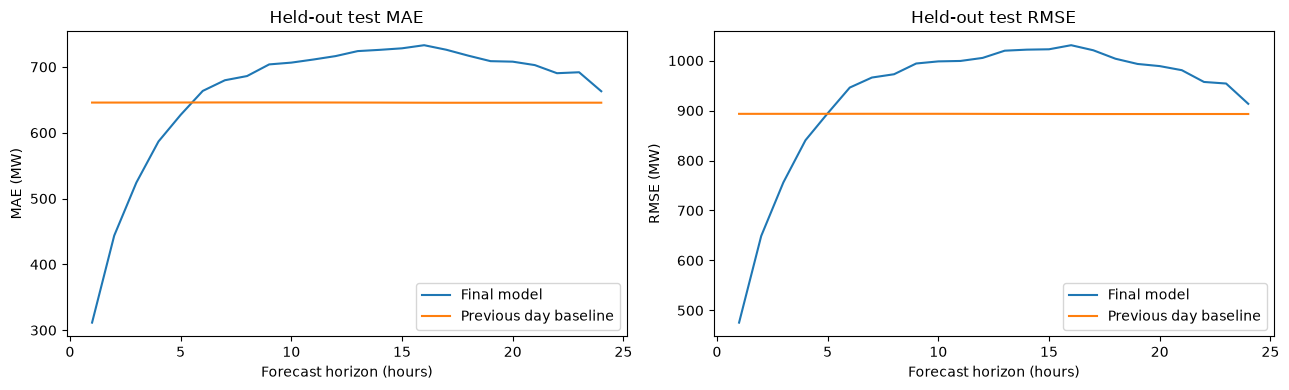

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, group in test_horizon_errors.groupby('model'):
    axes[0].plot(group['horizon_hours'], group['mae_mw'], label=name)
    axes[1].plot(group['horizon_hours'], group['rmse_mw'], label=name)
for axis, metric in zip(axes, ['MAE', 'RMSE']):
    axis.set_xlabel('Forecast horizon (hours)')
    axis.set_ylabel(f'{metric} (MW)')
    axis.set_title(f'Held-out test {metric}')
    axis.legend()
plt.tight_layout()
plt.show()


## Final findings and limitations

The initial comparison evaluated Random Forest and histogram gradient boosting
against a same-hour-yesterday baseline. Both algorithms were tested with full
history and a recent training window beginning in 2019. Recent-history gradient
boosting achieved the lowest validation MAE. Adding the previous 24 hourly
renewable readings reduced validation MAE from 568.51 MW to 529.52 MW, compared
with 603.02 MW for the baseline. The expanded model beat the baseline at all
24 validation forecast horizons and was selected before test evaluation.

### Held-out test results

The selected model was kept fitted on training data through 2023 and evaluated
at 15,120 hourly forecast origins from January 2025 to September 2026. Each
origin produced 24 predictions. The 362,880 forecast-target pairs overlap in
time and are not independent observations.

| Test measure | Selected model | Previous-day baseline |
| --- | ---: | ---: |
| Overall MAE | 661.65 MW | 645.79 MW |
| Overall RMSE | 942.55 MW | 893.25 MW |
| Overall signed bias | -335.29 MW | -0.05 MW |
| Low-generation MAE | 458.55 MW | 554.13 MW |
| Low-generation RMSE | 542.27 MW | 708.33 MW |
| Low-generation signed bias | +451.99 MW | +504.54 MW |

The validation improvement did not carry through to overall test accuracy:
the selected model's test MAE was approximately 2.5% higher than the baseline.
However, its MAE during low-generation periods was approximately 17.2% lower.
This supports a qualified conclusion: historical generation features provide
useful predictive information, but the selected ML model does not consistently
outperform a simple previous-day forecast on unseen periods.

### Interpretation and limitations

- Overall negative bias indicates underprediction, while positive bias during
  low-generation periods indicates overprediction. These opposing behaviours
  would be hidden by reporting only one aggregate signed error.
- Low generation was defined using the training-window 20th percentile
  (771.58 MW). This is an exploratory evaluation threshold, not an operational
  renewable sufficiency target. The model still overpredicts this group by
  approximately 452 MW on average, potentially overstating renewable availability.
- The coverage analysis shows increasing generation levels over time. Changing
  generation conditions are a plausible contributor to reduced test performance,
  but this experiment does not isolate their cause. The frozen model was not
  updated with 2024 observations before testing.
- Forecasting uses historical renewable generation and calendar features only.
  Weather, installed capacity, curtailment and external forecasts are excluded.
  The target follows Open Electricity's renewable definition, which includes
  some storage discharge; it is not a pure wind-and-solar measurement.
- Missing observations are retained on the timeline when calculating features,
  and incomplete examples are excluded. Scores describe the retained examples.
  The test period includes all of 2025 and part of 2026, rather than two complete
  calendar years.
- Point forecasts do not quantify uncertainty. Lower forecasting error alone
  does not establish that a renewable sufficiency assessment is reliable.

### Next implementation stage

The forecasting experiments are complete for this evaluation. Retain the
reported test results without tuning further against this test period. Future
model changes would require a new evaluation design, such as rolling temporal
validation with a separate untouched assessment period.

The expanded-history model and its feature schema are saved as
`A2/outputs/renewables/final_model.joblib`. Reusable feature preparation and
training should next be aligned with this notebook's chosen configuration.
The inference component will load the saved model and produce timestamped
24-hour renewable forecasts. Symbolic reasoning will combine these with aligned
demand forecasts and a separately justified renewable contribution target to
produce explanations and decision-support recommendations. Low renewable
contribution alone must not be interpreted as an overall electricity shortage.
